In [20]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

In [5]:
# Загружаем обучающую и тестовую части IMDB
(x_train_full, y_train_full), (x_test, y_test) = (
    tf.keras.datasets.imdb.load_data(num_words=20000)
)

print(f'{x_train_full.shape} x {y_train_full.shape}\n'
      f'{x_test.shape} x {y_test.shape}\n'
      f'{x_train_full[0][:20]} x {len(x_train_full[0])}\n')

(25000,) x (25000,)
(25000,) x (25000,)
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25] x 218



In [9]:
# Выделяем validation из обучающей части
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full,
    y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full
)

print(f'{x_val.shape}, {y_val.shape}')

(5000,), (5000,)


In [10]:
# Приводим отзывы к одинаковой длине
x_train_pad = tf.keras.utils.pad_sequences(x_train, maxlen=200, padding='post', truncating='post')
x_val_pad = tf.keras.utils.pad_sequences(x_val, maxlen=200, padding='post', truncating='post')
x_test_pad = tf.keras.utils.pad_sequences(x_test, maxlen=200, padding='post', truncating='post')

print(f'{x_train_pad.shape}\n{x_val_pad.shape}\n{x_test_pad.shape}\n')

(20000, 200)
(5000, 200)
(25000, 200)



In [11]:
# Фиксируем случайность для воспроизводимости
tf.keras.utils.set_random_seed(42)

# Создаем модель
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(200,), dtype='int32'),
    tf.keras.layers.Embedding(20000, 64, mask_zero=True),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.Dense(1, activation='sigmoid'),
])

model.summary()

C:\Users\Alex\PycharmProjects\JupyterProject\.venv\Lib\site-packages\keras\src\layers\layer.py:1077: UserWarning: Layer 'lstm' (of type LSTM) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,089 (5.01 MB)

 Trainable params: 1,313,089 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Настраиваем Adam оптимизатор, функцию потерь и метрику
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy'],
)

In [13]:
# Обучаем модель с ранней остановкой, Adam, 10 эпох
callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True,
)

history = model.fit(
    x_train_pad,
    y_train,
    validation_data=(x_val_pad, y_val),
    epochs=10,
    batch_size=64,
    callbacks=[callback],
)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 16s 47ms/step - accuracy: 0.7822 - loss: 0.4573 - val_accuracy: 0.8480 - val_loss: 0.3534
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9071 - loss: 0.2492 - val_accuracy: 0.8466 - val_loss: 0.3823
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 14s 45ms/step - accuracy: 0.9345 - loss: 0.1868 - val_accuracy: 0.8042 - val_loss: 0.5683


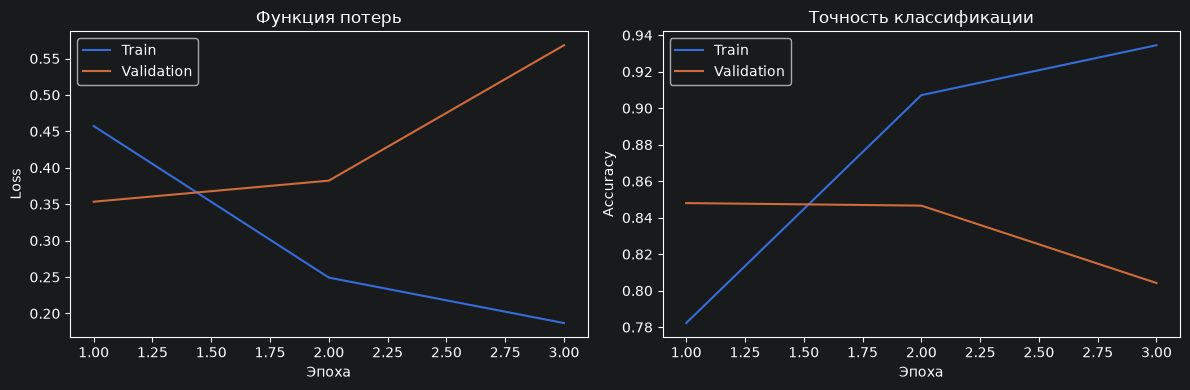

In [16]:
# Сравниваем динамику обучения на train и validation
epochs = range(1, len(history.history['loss']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(epochs, history.history['loss'], label='Train')
ax[0].plot(epochs, history.history['val_loss'], label='Validation')
ax[0].set_title('Функция потерь')
ax[0].set_xlabel('Эпоха')
ax[0].set_ylabel('Loss')
ax[0].legend()

ax[1].plot(epochs, history.history['accuracy'], label='Train')
ax[1].plot(epochs, history.history['val_accuracy'], label='Validation')
ax[1].set_title('Точность классификации')
ax[1].set_xlabel('Эпоха')
ax[1].set_ylabel('Accuracy')
ax[1].legend()

plt.tight_layout()
plt.show()

In [24]:
# Оцениваем модель на тестовой выборке
test_loss, test_accuracy = model.evaluate(
    x_test_pad, y_test
)
print(f'{test_loss} -> {test_accuracy}')

782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.8446 - loss: 0.3633 
0.36334264278411865 -> 0.8445600271224976


782/782 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step


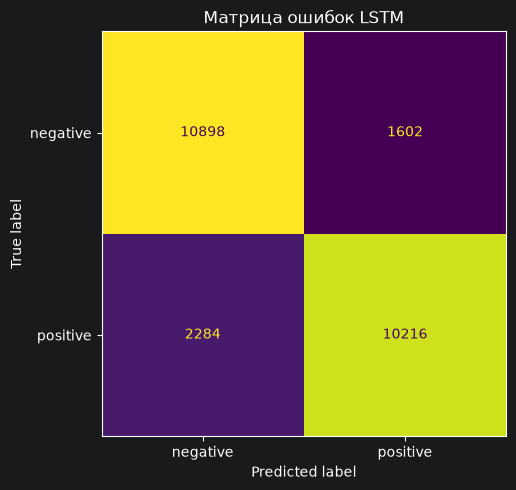

In [29]:
predictions = model.predict(x_test_pad)
y_pred = (predictions.ravel() >= 0.5).astype(int)

# Строим матрицу ошибок LSTM на тестовой выборке
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_true=y_test,
    y_pred=y_pred,
    labels=[0, 1],
    display_labels=['negative', 'positive'],
    ax=ax,
    colorbar=False,
    values_format='d',
)

ax.set_title('Матрица ошибок LSTM')
plt.tight_layout()
plt.show()

Модель LSTM досягла точності 84,46% на тестовій вибірці IMDB. Рання зупинка відновила ваги першої епохи, після якої спостерігалося перенавчання. Модель частіше помилялася на позитивних відгуках.